In [1]:
#4(a)
import pandas as pd
import numpy as np

# Load the dataset
data = pd.read_csv("MSFT_stock.csv")

# Calculate log returns
data['log_return'] = np.log(data['Close'].shift(-1) / data['Close'])

# Drop the last row since there is no log return for the last day
data = data.dropna()

# Calculate sample mean and sample variance
sample_mean = np.mean(data['log_return'])
sample_variance = np.var(data['log_return'])

# Print the results
print("Sample Mean (r):", sample_mean)
print("Sample Variance (s^2_r):", sample_variance)


Sample Mean (r): 0.0008868566305898708
Sample Variance (s^2_r): 0.00046746342193624597


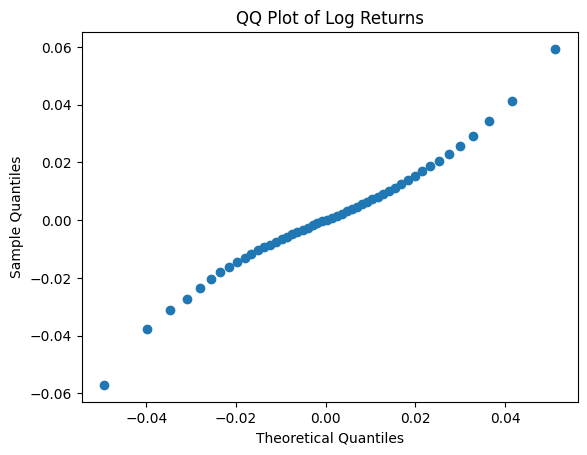

In [3]:
#4(b)
import matplotlib.pyplot as plt
import scipy.stats as stats

# Determine sample quantiles
sample_quantiles = np.quantile(data['log_return'], np.arange(0.01, 1, 0.02))

# Determine theoretical quantiles from a normal distribution
theoretical_quantiles = stats.norm.ppf(np.arange(0.01, 1, 0.02), loc=sample_mean, scale=np.sqrt(sample_variance))

# Create QQ plot
plt.scatter(theoretical_quantiles, sample_quantiles)
plt.title('QQ Plot of Log Returns')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')
plt.show()


In [15]:
#5(a)
import pandas as pd
import numpy as np
from scipy.stats import binom

# Load the dataset
data = pd.read_csv("MSFT_stock.csv")

# Drop the last row since there is no log return for the last day
data = data.dropna()

# Calculate log returns
data['log_return'] = np.log(data['Close'].shift(-1) / data['Close'])

# Count the number of positive and negative log returns
positive_returns = np.sum(data['log_return'] > 0)
negative_returns = np.sum(data['log_return'] < 0)

# Perform the sign test
n = len(data['log_return'])
k = min(positive_returns, negative_returns)
p_value = 2 * binom.cdf(k, n, 0.5)  # multiplying by 2 for a two-tailed test
print(p_value)
# Check if the p-value is less than the significance level
alpha = 0.05
if p_value < alpha:
    print(f"Reject H0: p-value = {p_value:.9f}")
else:
    print(f"Fail to reject H0: p-value = {p_value:.4f}")


2.5663407113905564e-07
Reject H0: p-value = 0.000000257


In [17]:
#5(c)
import pandas as pd
import numpy as np
from scipy.stats import ttest_1samp

# Load the dataset
data = pd.read_csv("MSFT_stock.csv")

# Calculate log returns
data['log_return'] = np.log(data['Close'].shift(-1) / data['Close'])

# Drop the last row since there is no log return for the last day
data = data.dropna()

# Perform one-sample t-test
t_stat, p_value = ttest_1samp(data['log_return'], popmean=0)

# Check if the p-value is less than the significance level
alpha = 0.05
if p_value < alpha:
    print(f"Reject H0: p-value = {p_value:.6f}")
else:
    print(f"Fail to reject H0: p-value = {p_value:.4f}")


Reject H0: p-value = 0.000129
